# 04 — Vermeulen (2018) Tail Correction

Combines EFH survey with Forbes, estimates Pareto alpha (MLE + Gabaix-Ibragimov), fills the gap with conditional Pareto draws, appends Forbes, and uprates financial assets to national accounts (`CCNN_CFT_S14_AF_2018.xlsx`).

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import openpyxl

from utils import load_root
ROOT = load_root()

from source import shares as wealth
from source import figures as figplots
from source import pareto as vermeulen

%load_ext autoreload
%autoreload 2

[utils] Project root loaded successfully: /home/choroy/Documents/doctorado/S4/ENECO894/problem-set


In [2]:
DATAPATH = ROOT / 'data/processed'
FIGURESPATH = ROOT / 'figures/p2/'

efh_df = pd.read_parquet(DATAPATH / 'efh_2021_clean.parquet')
forbes_df = pd.read_parquet(DATAPATH / 'forbes_2021_clp.parquet')

# baseline shares for comparison
res = wealth.weighted_shares(efh_df, wealth_col='net_wealth')
res

{'bottom50': np.float64(0.06786093859016812),
 'top10': np.float64(0.5140417244476595),
 'top1': np.float64(0.14610434495560246)}

**2.ii Vermeulen (2018) with Forbes — Pareto + uprating**

In [3]:
# NOTE: efh_df ya viene con uprating de la celda siguiente en re-runs; para evitar doble conteo recarga limpio aqui
# Si ya corriste vermeulen_corr, vuelve a correr la celda de carga (Data load) antes de esta
w = pd.concat([efh_df['net_wealth'], forbes_df['networth-clp']], ignore_index=True)
wt = pd.concat([efh_df['factor'], pd.Series([1]*len(forbes_df))], ignore_index=True)
for W_MIN in [380_000_000, 759_100_000, None]:
    W_MIN_E = vermeulen._wmin_from_percentile(efh_df, 'net_wealth', 'factor', p=0.99) if W_MIN is None else W_MIN
    alpha_mle = vermeulen.estimate_alpha_pareto(w, wt, W_MIN_E, method='mle')
    alpha_reg = vermeulen.estimate_alpha_pareto(w, wt, W_MIN_E, method='reg')
    print(f"W_MIN={W_MIN_E/1e6:.1f}M alpha_mle={alpha_mle:.3f} alpha_reg={alpha_reg:.3f} (efh uprated={('act_fin' in efh_df and float((efh_df['act_fin']*efh_df['factor']).sum())<5e14)})")


W_MIN=380.0M alpha_mle=1.907 alpha_reg=2.174 (efh uprated=False)
W_MIN=759.1M alpha_mle=2.449 alpha_reg=2.198 (efh uprated=False)
W_MIN=812.1M alpha_mle=2.619 alpha_reg=2.173 (efh uprated=False)


In [4]:
bde_path = ROOT / 'data/BDE/CCNN_CFT_S14_AF_2018.xlsx'
if bde_path.exists():
    wb = openpyxl.load_workbook(bde_path, data_only=True, read_only=True)
    ws = wb['Cuadro']
    macro_fin = 426112.5039 * 1e9  # a CLP
    cur_fin = (efh_df['act_fin'] * efh_df['factor']).sum()
    lam_fin = macro_fin / cur_fin if cur_fin else 1
    print(f"uprating financiero lambda={lam_fin:.3f}")
    # avoid double uprating on re-runs: reload clean frame if already uprated
    if abs(lam_fin - 1.0) < 0.02 and 'efh_clean_backup' not in globals():
        efh_df = pd.read_parquet(DATAPATH / 'efh_2021_clean.parquet')
        cur_fin = (efh_df['act_fin'] * efh_df['factor']).sum()
        lam_fin = macro_fin / cur_fin if cur_fin else 1
        print(f"reloaded clean, lambda={lam_fin:.3f}")
    efh_df['act_fin'] = efh_df['act_fin'] * lam_fin
    efh_df['net_wealth'] = efh_df['act_toth'] - efh_df['d_toth']

# baseline: MLE at 380m (alpha ~1.86) — best QQ fit
efh_corr, alpha = vermeulen.vermeulen_correction(efh_df,
                                                 forbes_df,
                                                 w_min=380_000_000,
                                                 wealth_col='net_wealth',
                                                 weight_col='factor',
                                                 forbes_wealth_col='networth-clp',
                                                 alpha_method='mle')

res_corr = wealth.weighted_shares(efh_corr, wealth_col='net_wealth')
print('raw ', res)
print('corr', res_corr)
print(f"alpha used (380m, mle): {alpha:.3f}")


uprating financiero lambda=0.479


raw  {'bottom50': np.float64(0.06786093859016812), 'top10': np.float64(0.5140417244476595), 'top1': np.float64(0.14610434495560246)}
corr {'bottom50': np.float64(0.056064431255717306), 'top10': np.float64(0.5362265015629983), 'top1': np.float64(0.15845089699068307)}
alpha used (380m, mle): 1.859


saved figure to /home/choroy/Documents/doctorado/S4/ENECO894/problem-set/figures/p2/alpha_sensitivity.pdf


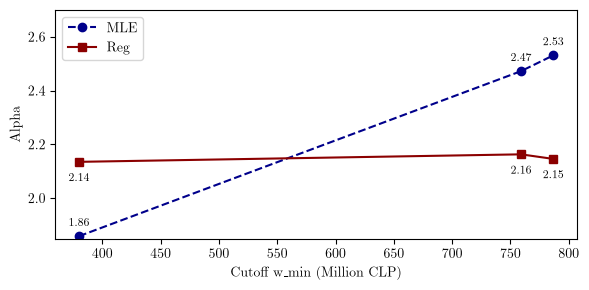

In [5]:
# sensitivity of alpha to w_min cutoff
wmins = [380_000_000, 759_100_000, vermeulen._wmin_from_percentile(efh_df, 'net_wealth', 'factor', p=0.99)]
w_all = pd.concat([efh_df['net_wealth'], forbes_df['networth-clp']], ignore_index=True)
wt_all = pd.concat([efh_df['factor'], pd.Series([1]*len(forbes_df))], ignore_index=True)
alphas_mle = [vermeulen.estimate_alpha_pareto(w_all, wt_all, w0, method='mle') for w0 in wmins]
alphas_reg = [vermeulen.estimate_alpha_pareto(w_all, wt_all, w0, method='reg') for w0 in wmins]


fig, ax = plt.subplots(1, 1, figsize=(6, 3))
figplots.plot_alpha_sensitivity(wmins, alphas_mle, alphas_reg, fig, ax)
plt.tight_layout()
figplots.save_fig(FIGURESPATH / 'alpha_sensitivity.pdf', fig, dpi=300)
plt.show()


saved figure to /home/choroy/Documents/doctorado/S4/ENECO894/problem-set/figures/p2/shares_vermeulen.pdf


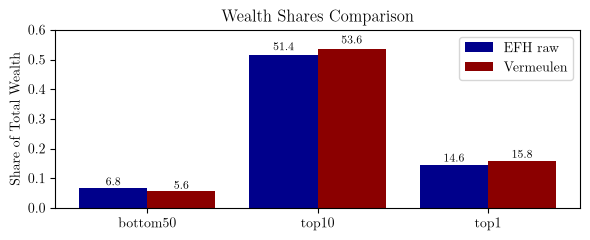

In [6]:
fig, ax = plt.subplots(1, 1, figsize=(6, 2.5))
figplots.plot_shares_comparison([res, res_corr], labels=['EFH raw', 'Vermeulen'], fig=fig, ax=ax)
plt.tight_layout()
figplots.save_fig(FIGURESPATH / 'shares_vermeulen.pdf', fig, dpi=300)
plt.show()


saved figure to /home/choroy/Documents/doctorado/S4/ENECO894/problem-set/figures/p2/pareto_qq.pdf


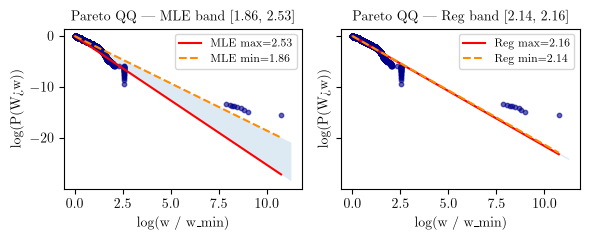

MLE: ['1.859', '2.473', '2.531'] | Reg: ['2.135', '2.163', '2.146']


In [7]:
w_plot = pd.concat([efh_df['net_wealth'], forbes_df['networth-clp']], ignore_index=True)
wt_plot = pd.concat([efh_df['factor'], pd.Series([1]*len(forbes_df))], ignore_index=True)
wmins_plot = [380_000_000, 759_100_000, vermeulen._wmin_from_percentile(efh_df, 'net_wealth', 'factor', p=0.99)]
a_mle_all = [vermeulen.estimate_alpha_pareto(w_plot, wt_plot, w0, method='mle') for w0 in wmins_plot]
a_reg_all = [vermeulen.estimate_alpha_pareto(w_plot, wt_plot, w0, method='reg') for w0 in wmins_plot]
W0_BASE = min(wmins_plot)  # common empirical tail for both panels

fig, axes = plt.subplots(1, 2, figsize=(6, 2.5), sharey=True)
for ax, a_all, method in zip(axes, [a_mle_all, a_reg_all], ['MLE', 'Reg']):
    a_min, a_max = min(a_all), max(a_all)
    fig, ax = figplots.plot_pareto_qq(w_plot, wt_plot, W0_BASE, a_max, fig, ax, 
                                      alphas={f'{method} max={a_max:.2f}': a_max, f'{method} min={a_min:.2f}': a_min})
    xs = np.linspace(0, ax.get_xlim()[1], 100)
    ax.fill_between(xs, -a_max*xs, -a_min*xs, alpha=0.15)
    ax.set_title(f"Pareto QQ — {method} band [{a_min:.2f}, {a_max:.2f}]", fontsize=10)
    ax.legend(fontsize=8)

plt.tight_layout()
figplots.save_fig(FIGURESPATH / 'pareto_qq.pdf', fig, dpi=300)
plt.show()
print(f"MLE: {['%.3f' % a for a in a_mle_all]} | Reg: {['%.3f' % a for a in a_reg_all]}")


saved figure to /home/choroy/Documents/doctorado/S4/ENECO894/problem-set/figures/p2/vermeulen_tail.pdf


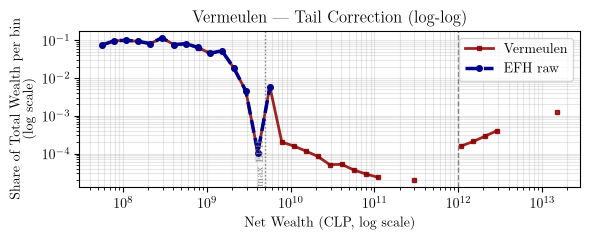

In [8]:
fig, ax = plt.subplots(1, 1, figsize=(6, 2.5))
figplots.plot_vermeulen_comparison(efh_df, efh_corr, forbes_df, fig, ax)
plt.tight_layout()
figplots.save_fig(FIGURESPATH / 'vermeulen_tail.pdf', fig, dpi=300)
plt.show()
